In [1]:
!pip install ucimlrepo


   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 343.6 kB/s eta 0:00:31
   - -------------------------------------- 0.5/10.9 MB 343.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.8/10.9 MB 411.6 kB/s eta 0:00:25
   -- ------------------------------------- 0.8/10.9 MB 411.6 kB/s eta 0:00:25
   -- ------------------------------------- 0.8/10.9 MB 411.6 kB/s eta 0:00:25
   --- ------------------------------------ 1


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Load medical dataset
medical = fetch_ucirepo(id=161)

# Separate features and target
X = medical.data.features.copy()
y = medical.data.targets.copy()

# Combine dataset
df = pd.concat([X, y], axis=1)

# Rename columns
df.columns = ['BI-RADS', 'Age', 'Shape',
              'Margin', 'Density', 'Severity']

# Replace missing value symbols
df.replace('?', np.nan, inplace=True)

print("Medical Diagnostics Dataset Loaded Successfully!")
print(df.head())

Medical Diagnostics Dataset Loaded Successfully!
   BI-RADS   Age  Shape  Margin  Density  Severity
0      5.0  67.0    3.0     5.0      3.0         1
1      4.0  43.0    1.0     1.0      NaN         1
2      5.0  58.0    4.0     5.0      3.0         1
3      4.0  28.0    1.0     1.0      3.0         0
4      5.0  74.0    1.0     5.0      NaN         1


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (961, 6)

First 5 Records:
   BI-RADS   Age  Shape  Margin  Density  Severity
0      5.0  67.0    3.0     5.0      3.0         1
1      4.0  43.0    1.0     1.0      NaN         1
2      5.0  58.0    4.0     5.0      3.0         1
3      4.0  28.0    1.0     1.0      3.0         0
4      5.0  74.0    1.0     5.0      NaN         1

Column Names:
Index(['BI-RADS', 'Age', 'Shape', 'Margin', 'Density', 'Severity'], dtype='str')

Data Types:
BI-RADS     float64
Age         float64
Shape       float64
Margin      float64
Density     float64
Severity      int64
dtype: object

Missing Values:
BI-RADS      2
Age          5
Shape       31
Margin      48
Density     76
Severity     0
dtype: int64


In [4]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

BI-RADS     float64
Age         float64
Shape       float64
Margin      float64
Density     float64
Severity      int64
dtype: object

Missing Values:
BI-RADS      2
Age          5
Shape       31
Margin      48
Density     76
Severity     0
dtype: int64


In [5]:
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
          BI-RADS         Age       Shape      Margin     Density    Severity
count  959.000000  956.000000  930.000000  913.000000  885.000000  961.000000
mean     4.348279   55.487448    2.721505    2.796276    2.910734    0.463059
std      1.783031   14.480131    1.242792    1.566546    0.380444    0.498893
min      0.000000   18.000000    1.000000    1.000000    1.000000    0.000000
25%      4.000000   45.000000    2.000000    1.000000    3.000000    0.000000
50%      4.000000   57.000000    3.000000    3.000000    3.000000    0.000000
75%      5.000000   66.000000    4.000000    4.000000    3.000000    1.000000
max     55.000000   96.000000    4.000000    5.000000    4.000000    1.000000


In [8]:
from sklearn.model_selection import train_test_split

# Select input features
X = df[['Age', 'Shape', 'Margin', 'Density']]

# Select target column
y = df['Severity']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (768, 4)
Testing data: (193, 4)
Training target: (768,)
Testing target: (193,)


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [9]:
numeric_features = ['Age']

categorical_features = ['Shape', 'Margin', 'Density']

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Age']
Categorical Features: ['Shape', 'Margin', 'Density']


In [10]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [11]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [12]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("ColumnTransformer Created Successfully!")

ColumnTransformer Created Successfully!


In [16]:
final_pipeline = Pipeline([
    ('preprocessing', preprocessor)
])

# Fit only training data
X_train_processed = final_pipeline.fit_transform(X_train)

# Transform testing data
X_test_processed = final_pipeline.transform(X_test)

print("Preprocessing Completed Successfully!")
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Preprocessing Completed Successfully!
Training Data Shape: (768, 14)
Testing Data Shape: (193, 14)


In [17]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization Libraries Imported Successfully!")

Matplotlib is building the font cache; this may take a moment.


Visualization Libraries Imported Successfully!


In [19]:
correlation = df[
    ['Age', 'Shape', 'Margin', 'Density', 'Severity']
].corr()

print(correlation)

               Age     Shape    Margin   Density  Severity
Age       1.000000  0.364077  0.411355  0.028954  0.432066
Shape     0.364077  1.000000  0.742211  0.078666  0.563308
Margin    0.411355  0.742211  1.000000  0.109392  0.574919
Density   0.028954  0.078666  0.109392  1.000000  0.064010
Severity  0.432066  0.563308  0.574919  0.064010  1.000000


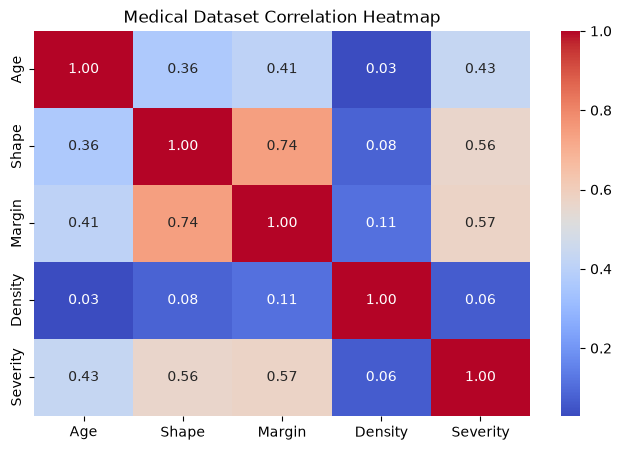

In [20]:
plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Medical Dataset Correlation Heatmap")
plt.show()

In [21]:
from sklearn.feature_selection import mutual_info_classif

import pandas as pd

In [22]:
# Convert processed data into dense format
X_train_dense = X_train_processed.toarray()

# Identify categorical features
feature_names = final_pipeline.named_steps[
    'preprocessing'
].get_feature_names_out()

discrete_mask = [
    name.startswith('cat__') for name in feature_names
]

# Calculate mutual information
importance = mutual_info_classif(
    X_train_dense,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

# Create importance table
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

print(importance_df)

             Feature  Importance
5    cat__Margin_1.0    0.182429
4     cat__Shape_4.0    0.147646
0           num__Age    0.115051
1     cat__Shape_1.0    0.058903
2     cat__Shape_2.0    0.050027
9    cat__Margin_5.0    0.046774
8    cat__Margin_4.0    0.045458
7    cat__Margin_3.0    0.010014
11  cat__Density_2.0    0.003963
12  cat__Density_3.0    0.002971
6    cat__Margin_2.0    0.000194
3     cat__Shape_3.0    0.000106
13  cat__Density_4.0    0.000009
10  cat__Density_1.0    0.000002


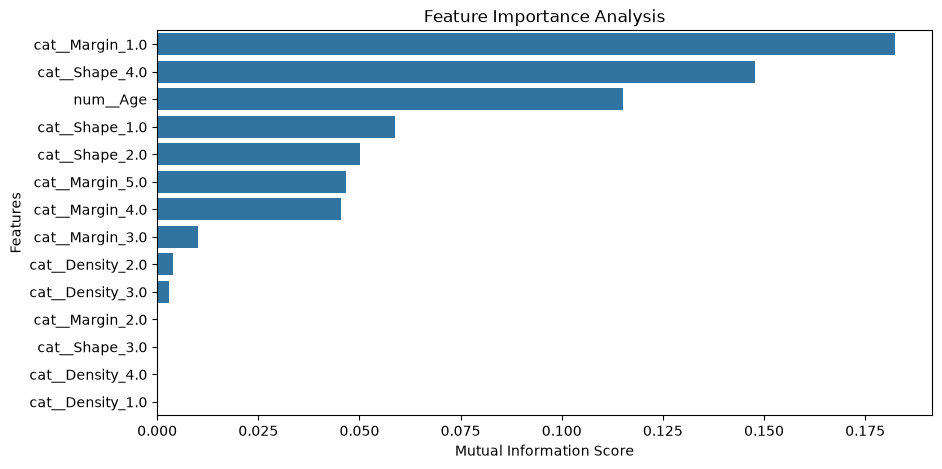

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance Analysis")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.show()

In [24]:
print("FINAL PIPELINE VERIFICATION")

print("Training Data:", X_train_processed.shape)
print("Testing Data:", X_test_processed.shape)

print("Missing Values in Training:",
      np.isnan(X_train_processed.toarray()).sum())

print("Missing Values in Testing:",
      np.isnan(X_test_processed.toarray()).sum())

print("\nPreprocessing Completed Successfully!")

FINAL PIPELINE VERIFICATION
Training Data: (768, 14)
Testing Data: (193, 14)
Missing Values in Training: 0
Missing Values in Testing: 0

Preprocessing Completed Successfully!


In [25]:
# TASK 4: SUPERVISED CLASSIFICATION MODELING & TUNING

In [27]:
%pip install scikit-learn xgboost lightgbm joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("\nTarget Variable Distribution:")
print(y_train.value_counts())

print("\nTarget Classes:")
print(y_train.unique())

Training Data Shape: (768, 14)
Testing Data Shape: (193, 14)

Target Variable Distribution:
Severity
0    412
1    356
Name: count, dtype: int64

Target Classes:
[1 0]


In [29]:
## 1. Logistic Regression Model

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create Logistic Regression model
lr = LogisticRegression(max_iter=1000, random_state=42)

# Hyperparameter values
param_grid = {
    'C': [0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs']
}

# Stratified K-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Grid Search
grid_lr = GridSearchCV(
    lr,
    param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

# Train the model
grid_lr.fit(X_train_processed, y_train)

# Best model
best_lr = grid_lr.best_estimator_

print("Best Parameters:", grid_lr.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_lr.best_score_)
print("Logistic Regression Training Completed!")

Best Parameters: {'C': 0.1, 'solver': 'liblinear'}
Best Cross-Validation ROC-AUC: 0.862182831865651
Logistic Regression Training Completed!


In [32]:
## 2. Random Forest Classifier

In [33]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf = RandomForestClassifier(random_state=42)

# Hyperparameter values
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

# Grid Search
grid_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

# Train model
grid_rf.fit(X_train_processed, y_train)

# Best model
best_rf = grid_rf.best_estimator_

print("Best Parameters:", grid_rf.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_rf.best_score_)
print("Random Forest Training Completed!")

Best Parameters: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross-Validation ROC-AUC: 0.8604535944074018
Random Forest Training Completed!


In [34]:
## 3. XGBoost Classifier

In [35]:
from xgboost import XGBClassifier

# Create XGBoost model
xgb = XGBClassifier(
    eval_metric='logloss',
    random_state=42
)

# Hyperparameter values
param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.01, 0.1]
}

# Grid Search
grid_xgb = GridSearchCV(
    xgb,
    param_grid_xgb,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

# Train model
grid_xgb.fit(X_train_processed, y_train)

# Best model
best_xgb = grid_xgb.best_estimator_

print("Best Parameters:", grid_xgb.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_xgb.best_score_)
print("XGBoost Training Completed!")

Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200}
Best Cross-Validation ROC-AUC: 0.8555947682864747
XGBoost Training Completed!


In [36]:
## 4. LightGBM Classifier

In [37]:
from lightgbm import LGBMClassifier

# Create LightGBM model
lgbm = LGBMClassifier(
    random_state=42,
    verbosity=-1
)

# Hyperparameter values
param_grid_lgbm = {
    'n_estimators': [100, 200],
    'max_depth': [-1, 5, 10],
    'learning_rate': [0.01, 0.1]
}

# Grid Search
grid_lgbm = GridSearchCV(
    lgbm,
    param_grid_lgbm,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

# Train model
grid_lgbm.fit(X_train_processed, y_train)

# Best model
best_lgbm = grid_lgbm.best_estimator_

print("Best Parameters:", grid_lgbm.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_lgbm.best_score_)
print("LightGBM Training Completed!")

Best Parameters: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 200}
Best Cross-Validation ROC-AUC: 0.8482496572802143
LightGBM Training Completed!


In [38]:
## 5. Model Evaluation and Comparison

In [39]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Store all trained models
models = {
    'Logistic Regression': best_lr,
    'Random Forest': best_rf,
    'XGBoost': best_xgb,
    'LightGBM': best_lgbm
}

results = []

# Evaluate each model
for name, model in models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Create comparison table
comparison_df = pd.DataFrame(results)

print("MODEL COMPARISON TABLE")
display(comparison_df.round(4))

MODEL COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8187,0.7647,0.8764,0.8168,0.8897
1,Random Forest,0.8135,0.7573,0.8764,0.8125,0.8814
2,XGBoost,0.8083,0.7500,0.8764,0.8083,0.8892
3,LightGBM,0.8135,0.7524,0.8876,0.8144,0.8710


In [40]:
## 6. Confusion Matrix Visualization

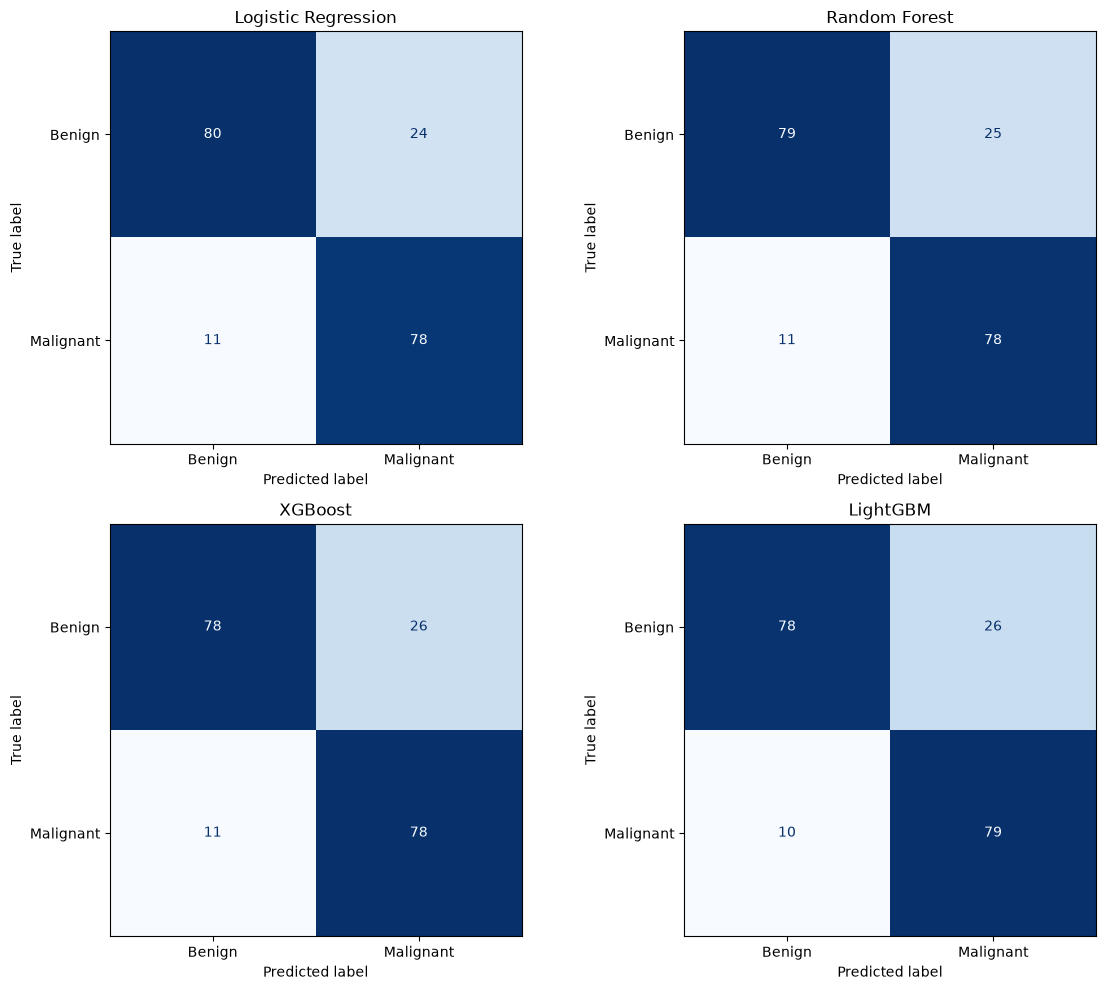

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.ravel(), models.items()):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Benign', 'Malignant']
    )

    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [42]:
## 7. ROC-AUC Curve Comparison

<Figure size 900x700 with 0 Axes>

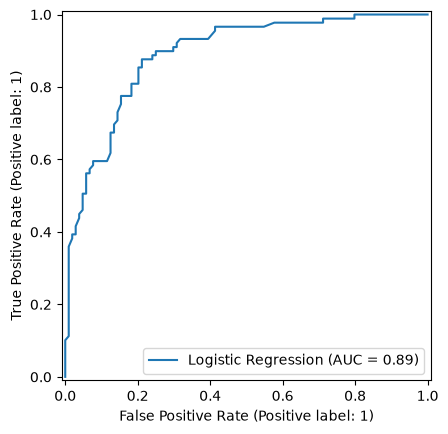

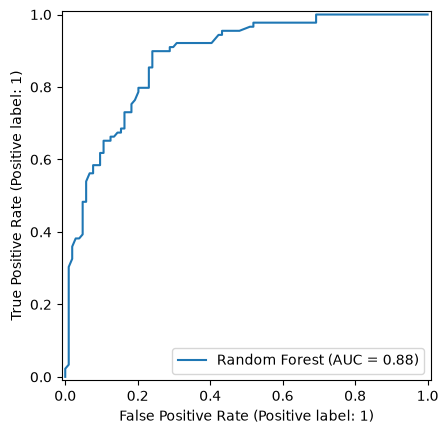

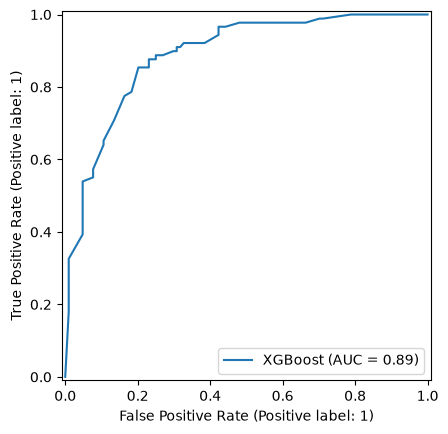

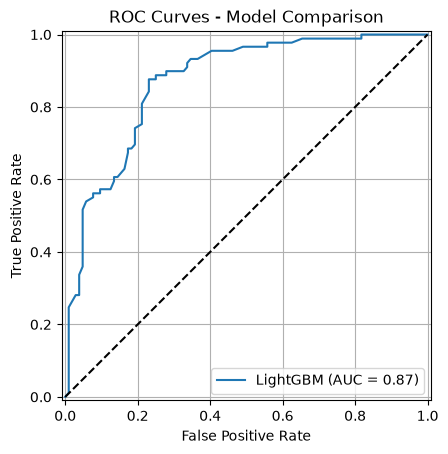

In [43]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 7))

for name, model in models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test_processed,
        y_test,
        name=name
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curves - Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

In [44]:
cv_scores = {
    'Logistic Regression': grid_lr.best_score_,
    'Random Forest': grid_rf.best_score_,
    'XGBoost': grid_xgb.best_score_,
    'LightGBM': grid_lgbm.best_score_
}

champion_name = max(cv_scores, key=cv_scores.get)
champion_model = models[champion_name]

print("CHAMPION MODEL:", champion_name)
print("BEST CV ROC-AUC:", round(cv_scores[champion_name], 4))

CHAMPION MODEL: Logistic Regression
BEST CV ROC-AUC: 0.8622


In [46]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(champion_model, "models/champion_model.joblib")

print("Champion model saved successfully!")

Champion model saved successfully!


In [47]:
import os

os.makedirs("results", exist_ok=True)

comparison_df.to_csv("results/model_comparison.csv", index=False)

print("Model comparison report saved successfully!")

Model comparison report saved successfully!
